# LAB 05 – BÀI TẬP THỰC HÀNH PHẦN 2: SUPPORT VECTOR MACHINE (SVM)

## Thư viện và hàm dùng chung

In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

import glob, os
def find_file(patterns):
    """Tìm file CSV ở thư mục hiện tại hoặc trong /kaggle/input (khi chạy trên Kaggle)."""
    for p in patterns:
        hits = glob.glob(p) + glob.glob('/kaggle/input/**/' + p, recursive=True)
        if hits: return hits[0]
    raise FileNotFoundError('Không thấy file ' + str(patterns) + ' - hãy tải từ Kaggle và đặt cạnh notebook.')

run_svm(X, y, preprocessor, name):
1. Chia train/test 80:20 (stratify).
2. So sánh 4 kernel (linear, poly, rbf, sigmoid) với tham số mặc định bằng CV 5 lần trên tập train.
3. GridSearchCV trên kernel, C, gamma (và degree cho poly).
4. Đánh giá một lần trên tập test: Accuracy, ROC AUC, báo cáo phân loại, confusion matrix; so sánh điểm train/test để kiểm tra quá khớp.

In [10]:
def run_svm(X, y, preprocessor, name):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    print(f'[{name}] train={X_train.shape}, test={X_test.shape}')
    cv = StratifiedKFold(5, shuffle=True, random_state=42)

    # 1) So sánh kernel với tham số mặc định
    rows = []
    for k in ['linear', 'poly', 'rbf', 'sigmoid']:
        pipe = Pipeline([('prep', preprocessor), ('svc', SVC(kernel=k))])
        sc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
        rows.append({'kernel': k, 'CV accuracy (mean)': sc.mean(), 'CV std': sc.std()})
    kdf = pd.DataFrame(rows).round(4); print(kdf.to_string(index=False))
    kdf.set_index('kernel')['CV accuracy (mean)'].plot.bar(figsize=(5, 3), ylim=(0, 1), rot=0)
    plt.title(f'{name} - so sánh kernel (CV accuracy)'); plt.show()

    # 2) GridSearchCV
    grid = GridSearchCV(Pipeline([('prep', preprocessor), ('svc', SVC(probability=True))]),
                        [{'svc__kernel': ['linear'], 'svc__C': [0.1, 1, 10, 100]},
                         {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1]},
                         {'svc__kernel': ['poly'], 'svc__C': [0.1, 1, 10], 'svc__degree': [2, 3], 'svc__gamma': ['scale']}],
                        cv=cv, scoring='accuracy', n_jobs=-1, return_train_score=True)
    grid.fit(X_train, y_train)
    print('Tham số tốt nhất:', grid.best_params_)
    print('Accuracy CV: %.4f' % grid.best_score_)

    # 3) Đánh giá trên tập test
    best = grid.best_estimator_
    pred = best.predict(X_test); proba = best.predict_proba(X_test)[:, 1]
    print('Accuracy train: %.4f | Accuracy test: %.4f | ROC AUC test: %.4f' % (
        best.score(X_train, y_train), accuracy_score(y_test, pred), roc_auc_score(y_test, proba)))
    print(classification_report(y_test, pred))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(cmap='Blues', colorbar=False)
    plt.title(f'{name} - confusion matrix (tập test)'); plt.show()
    return grid, (X_test, y_test)

# BÀI 1 – BỆNH TIỂU ĐƯỜNG
## 1.1 Nạp dữ liệu và khám phá

In [11]:
diab = pd.read_csv(find_file(['diabetes.csv', '*diabetes*.csv']))
target_col = next((col for col in ('Outcome', 'diabetes') if col in diab.columns), None)
if target_col is None:
    raise ValueError(f"Target column not found. Available columns: {diab.columns.tolist()}")

max_rows = 1000
if len(diab) > max_rows:
    diab, _ = train_test_split(diab, train_size=max_rows, stratify=diab[target_col], random_state=42)
    print(f"Using a stratified sample of {max_rows:,} rows to keep SVM search tractable.")

print(diab.shape, f'| target={target_col}, positive rate={diab[target_col].mean():.3f}')
diab.describe().T[['count', 'mean', 'std', 'min', 'max']]

Using a stratified sample of 1,000 rows to keep SVM search tractable.
(1000, 9) | target=diabetes, positive rate=0.085


,count,mean,std,min,max
age,1000.0,42.57632,22.303511,0.24,80.00
hypertension,1000.0,0.07500,0.263523,0.00,1.00
heart_disease,1000.0,0.04100,0.198389,0.00,1.00
bmi,1000.0,27.20961,6.584692,10.30,70.96
HbA1c_level,1000.0,5.49270,1.053578,3.50,9.00
blood_glucose_level,1000.0,136.41700,40.229411,80.00,300.00
diabetes,1000.0,0.08500,0.279021,0.00,1.00


**Nhận xét dữ liệu:** Tập diabetes_prediction_dataset gốc có 100.000 mẫu, nhưng SVM có độ phức tạp huấn luyện tăng nhanh theo số mẫu (khoảng bậc hai đến bậc ba), nên code lấy mẫu phân tầng 1.000 dòng để GridSearchCV chạy được trong thời gian hợp lý. Lấy mẫu phân tầng giữ nguyên tỷ lệ lớp: vẫn 8,5% mắc bệnh (85 ca), nên sau khi chia 80:20 tập train có 800 mẫu (68 ca bệnh) và tập test có 200 mẫu (17 ca bệnh). Số ca bệnh trong tập test rất ít nên các chỉ số của lớp mắc bệnh dao động mạnh, chỉ sai một ca đã làm recall đổi khoảng 6 điểm phần trăm.

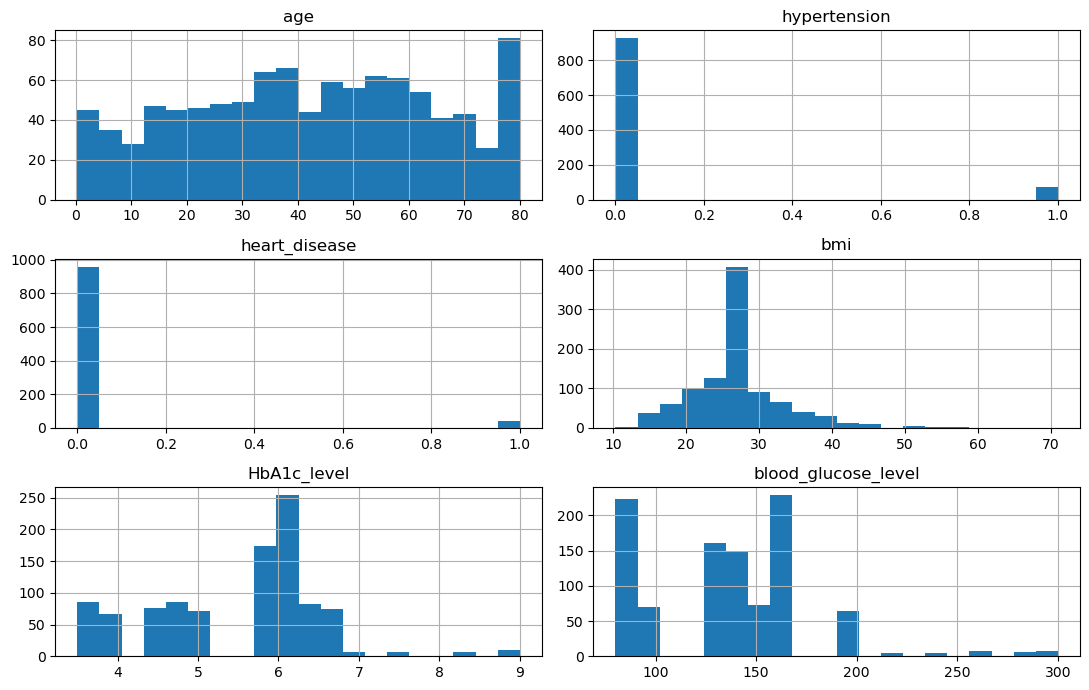

In [12]:
diab.drop(columns=target_col).select_dtypes(include=np.number).hist(bins=20, figsize=(11, 7)); plt.tight_layout(); plt.show()

**Nhận xét phân bố:** Các đặc trưng có thang đo rất khác nhau: age từ 0,24 đến 80, bmi từ 10 đến 71, HbA1c_level từ 3,5 đến 9, blood_glucose_level từ 80 đến 300, còn hypertension và heart_disease chỉ nhận 0 hoặc 1 và phần lớn là 0. Phân bố bmi tập trung quanh 27 và hơi lệch phải; HbA1c và đường huyết có dạng cụm rời rạc theo từng mức. Sự chênh lệch thang đo này (đường huyết lớn gấp hàng chục lần HbA1c) là lý do SVM cần chuẩn hóa dữ liệu, nếu không các biến có giá trị lớn sẽ chi phối khoảng cách trong kernel.

## 1.2 Tiền xử lý
Các giá trị 0 ở Glucose, BloodPressure, SkinThickness, Insulin, BMI thực chất là dữ liệu thiếu → đổi thành NaN rồi điền trung vị. Sau đó chuẩn hóa StandardScaler (đặt trong Pipeline, chỉ học trên tập train).

In [13]:
from sklearn.impute import SimpleImputer
d = diab.copy()
zero_missing = [col for col in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI'] if col in d.columns]
d[zero_missing] = d[zero_missing].replace(0, np.nan)
X1, y1 = d.drop(columns=target_col), d[target_col]
numeric_cols = X1.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X1.select_dtypes(exclude=np.number).columns.tolist()

def make_diabetes_preprocessor(scale_numeric=True):
    transformers = []
    if numeric_cols:
        numeric_steps = [('impute', SimpleImputer(strategy='median'))]
        if scale_numeric:
            numeric_steps.append(('scale', StandardScaler()))
        transformers.append(('num', Pipeline(numeric_steps), numeric_cols))
    if categorical_cols:
        categorical_steps = Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ])
        transformers.append(('cat', categorical_steps, categorical_cols))
    return ColumnTransformer(transformers)

prep1 = make_diabetes_preprocessor()

**Nhận xét tiền xử lý:** Bước đổi giá trị 0 thành thiếu cho các cột Glucose, BloodPressure, SkinThickness, Insulin, BMI (ghi ở phần mô tả trên) không có tác dụng với bộ dữ liệu này vì các cột đó không tồn tại; code đã lọc chỉ giữ những cột có mặt nên không gây lỗi. Pipeline thực tế được áp dụng gồm: với cột số thì điền trung vị rồi chuẩn hóa StandardScaler; với cột phân loại (gender, smoking_history) thì điền giá trị phổ biến nhất rồi mã hóa one-hot. Toàn bộ các bước này nằm trong pipeline nên chỉ học tham số từ tập train, tránh rò rỉ dữ liệu sang tập test.

## 1.3 Xây dựng, tối ưu và đánh giá SVM

[Diabetes] train=(800, 8), test=(200, 8)
 kernel  CV accuracy (mean)  CV std
 linear              0.9588  0.0116
   poly              0.9550  0.0092
    rbf              0.9625  0.0079
sigmoid              0.9325  0.0108


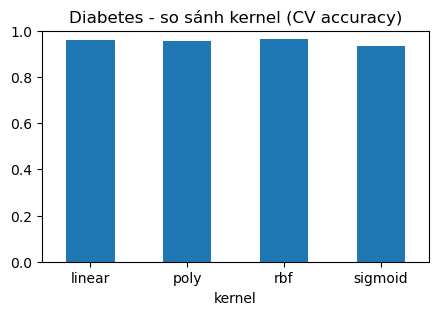

Tham số tốt nhất: {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Accuracy CV: 0.9625
Accuracy train: 0.9700 | Accuracy test: 0.9550 | ROC AUC test: 0.9132
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       183
           1       1.00      0.47      0.64        17

    accuracy                           0.95       200
   macro avg       0.98      0.74      0.81       200
weighted avg       0.96      0.95      0.95       200



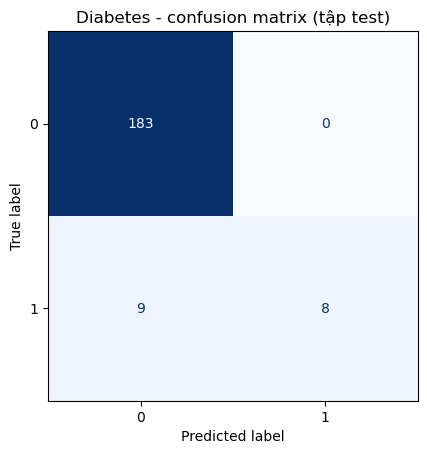

In [14]:
grid1, test1 = run_svm(X1, y1, prep1, 'Diabetes')

### Nhận xét kết quả bài 1 – SVM trên dữ liệu bệnh tiểu đường

**1. So sánh kernel (CV accuracy, tham số mặc định):** rbf đạt cao nhất (0,9625), tiếp theo là linear (0,9588), poly (0,9550) và thấp nhất là sigmoid (0,9325). Ba kernel đầu chênh nhau chưa đến 1 điểm phần trăm và độ lệch chuẩn giữa các fold khoảng 0,008 đến 0,012, nên chênh lệch này chưa có ý nghĩa thống kê; riêng sigmoid kém rõ hơn. Lưu ý mức nền (luôn đoán không bệnh) là 91,5%, nên kernel sigmoid chỉ hơn mức nền khoảng 2 điểm phần trăm.

**2. GridSearchCV:** Tham số tốt nhất là kernel rbf, C = 1, gamma = scale với accuracy kiểm định chéo 0,9625. Bộ tham số này trùng với kernel rbf mặc định, nghĩa là việc dò thêm C và gamma không cải thiện thêm so với cấu hình mặc định trên lượng dữ liệu nhỏ này.

**3. Kết quả trên tập test (200 mẫu):**
- Accuracy train 0,9700 và accuracy test 0,9550, chênh lệch nhỏ (khoảng 1,5 điểm phần trăm) nên không có dấu hiệu quá khớp đáng kể.
- ROC AUC test là 0,9132.
- Lớp không bệnh gần như hoàn hảo (precision 0,95, recall 1,00). Lớp mắc bệnh có precision 1,00 nhưng recall chỉ 0,47: mô hình chỉ phát hiện 8 trên 17 ca bệnh và bỏ sót 9 ca, trong khi không báo nhầm trường hợp nào.
- Accuracy 95,5% chỉ cao hơn mức nền 91,5% khoảng 4 điểm phần trăm, và F1 của lớp mắc bệnh chỉ 0,64 nên mô hình chưa tốt ở lớp quan trọng nhất.

**4. Nguyên nhân và hướng cải thiện:** Dữ liệu mất cân bằng (8,5% lớp bệnh) và chỉ có 68 ca bệnh để học, nên SVM ưu tiên phân loại đúng lớp đa số. Có thể cải thiện bằng class_weight=balanced, tăng cỡ mẫu (ví dụ 5.000 đến 10.000 dòng), chọn mô hình theo F1 hoặc recall, hoặc hạ ngưỡng quyết định. Cũng cần lưu ý ROC AUC của SVM ở đây (0,913) thấp hơn Phần 1 (khoảng 0,97) chủ yếu do chỉ huấn luyện trên 800 mẫu thay vì 80.000 mẫu, nên không so sánh trực tiếp hai con số này.

## 1.4 Tác động của việc chuẩn hóa dữ liệu (minh họa)
So sánh SVM RBF "có" và "không" chuẩn hóa trên cùng tập test.

In [15]:
Xtr, Xte, ytr, yte = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)
no_scale = Pipeline([('prep', make_diabetes_preprocessor(scale_numeric=False)), ('svc', SVC(kernel='rbf'))]).fit(Xtr, ytr)
with_scale = Pipeline([('prep', make_diabetes_preprocessor(scale_numeric=True)), ('svc', SVC(kernel='rbf'))]).fit(Xtr, ytr)
print('Without numeric scaling: test accuracy = %.4f' % no_scale.score(Xte, yte))
print('With numeric scaling   : test accuracy = %.4f' % with_scale.score(Xte, yte))

Without numeric scaling: test accuracy = 0.9400
With numeric scaling   : test accuracy = 0.9550


**Nhận xét tác động của chuẩn hóa:** Không chuẩn hóa cho accuracy test 0,9400 và có chuẩn hóa cho 0,9550, tức chuẩn hóa cải thiện 1,5 điểm phần trăm, tương đương 3 mẫu trên 200 mẫu test. Chênh lệch này nhỏ nên chưa đủ để kết luận chắc chắn chỉ từ một lần chia dữ liệu, nhưng đúng chiều với lý thuyết: SVM dựa vào khoảng cách nên cần đưa các đặc trưng về cùng thang đo. Tác động sẽ rõ hơn nếu so sánh bằng kiểm định chéo hoặc dùng các kernel nhạy hơn với thang đo như poly hoặc sigmoid. Dù hiệu quả cụ thể ở đây nhỏ, thực hành tốt vẫn là luôn đặt chuẩn hóa trong pipeline.

**Kết luận bài 1:** SVM kernel rbf (C = 1, gamma = scale) đạt accuracy test 95,5% và ROC AUC 0,913, nhưng chỉ phát hiện được 47% ca bệnh. Mô hình phân biệt tốt lớp đa số nhưng cần xử lý mất cân bằng lớp trước khi dùng cho mục đích sàng lọc.

# BÀI 2 – TÌNH TRẠNG ĐỘNG VẬT TRONG RỪNG
**Mục tiêu:** dự đoán con vật có ở tình trạng nguy hiểm (Dangerous: Yes/No) dựa trên tên loài (AnimalName) và các triệu chứng (symptoms1…symptoms5). Toàn bộ đặc trưng là phân loại nên phải mã hóa trước khi đưa vào SVM.
## 2.1 Nạp dữ liệu và khám phá

In [16]:
an = pd.read_csv(find_file(['animal_condition_train.csv', '*animal*.csv', 'data.csv']))
target = 'Dangerous' if 'Dangerous' in an.columns else an.columns[-1]
max_rows = 1000
if len(an) > max_rows:
    an, _ = train_test_split(an, train_size=max_rows, stratify=an[target], random_state=42)
    print(f"Using a stratified sample of {max_rows:,} rows to keep SVM search tractable.")
print(an.shape, '| label =', target)
print(an[target].value_counts(normalize=True).round(3))
print('Missing values:\n', an.isna().sum()[lambda s: s > 0])
an.head()

(871, 7) | label = Dangerous
Dangerous
Yes    0.977
No     0.023
Name: proportion, dtype: float64
Missing values:
 Dangerous    2
dtype: int64


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
0,Dog,Fever,Diarrhea,Vomiting,Weight loss,Dehydration,Yes
1,Dog,Fever,Diarrhea,Coughing,Tiredness,Pains,Yes
2,Dog,Fever,Diarrhea,Coughing,Vomiting,Anorexia,Yes
3,Dog,Fever,Difficulty breathing,Coughing,Lethargy,Sneezing,Yes
4,Dog,Fever,Diarrhea,Coughing,Lethargy,Blue Eye,Yes


**Nhận xét dữ liệu:** Tập dữ liệu có 871 dòng và 7 cột: tên loài (AnimalName), 5 triệu chứng (symptoms1 đến symptoms5) và nhãn Dangerous. Toàn bộ đặc trưng là dữ liệu phân loại. Nhãn cực kỳ mất cân bằng: 97,7% là Yes (nguy hiểm) và chỉ 2,3% là No. Một mô hình luôn đoán Yes đã đạt khoảng 97,7% accuracy, nên accuracy gần như vô nghĩa ở bài này. Ngoài ra cột Dangerous có 2 giá trị thiếu; trong code hiện tại hai dòng này bị chuyển thành chuỗi nan và vì khác với yes nên được gán nhãn 0 (No) một cách vô tình. Cách làm đúng hơn là loại bỏ hai dòng thiếu nhãn này trước khi huấn luyện, tuy ảnh hưởng đến kết quả là rất nhỏ.

## 2.2 Tiền xử lý
- Điền thiếu bằng mode (giá trị phổ biến nhất) cho mỗi cột.
- Mã hóa One-Hot (OneHotEncoder(handle_unknown='ignore')): mỗi giá trị của cột phân loại thành một cột 0/1. Không dùng mã số nguyên 0,1,2… vì SVM sẽ hiểu nhầm có thứ tự/khoảng cách.
- Nhãn Yes/No chuyển thành 1/0.
- Dữ liệu One-Hot đã ở thang 0/1 nên không cần StandardScaler.

In [17]:
from sklearn.impute import SimpleImputer
y2 = (an[target].astype(str).str.strip().str.lower() == 'yes').astype(int)
X2 = an.drop(columns=target).astype(str).replace('nan', np.nan)   # đảm bảo cột phân loại là chuỗi
cat_cols = X2.columns.tolist()
prep2 = ColumnTransformer([('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                                              ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)])
print('Số đặc trưng sau One-Hot:', prep2.fit_transform(X2).shape[1])

Số đặc trưng sau One-Hot: 1157


**Nhận xét tiền xử lý:** Sau mã hóa one-hot, 6 cột phân loại trở thành 1.157 đặc trưng 0/1, vì mỗi tên loài và mỗi triệu chứng khác nhau tạo ra một cột riêng. Ma trận rất thưa và có số chiều lớn so với 871 mẫu. Đây là tình huống mà SVM với kernel tuyến tính thường làm tốt, vì dữ liệu nhiều chiều có xu hướng dễ phân tách tuyến tính. Dữ liệu one-hot đã ở thang 0/1 nên không cần chuẩn hóa thêm.

## 2.3 Xây dựng, tối ưu và đánh giá SVM

[AnimalCondition] train=(696, 6), test=(175, 6)
 kernel  CV accuracy (mean)  CV std
 linear              0.9885  0.0057
   poly              0.9741  0.0035
    rbf              0.9741  0.0035
sigmoid              0.9785  0.0045


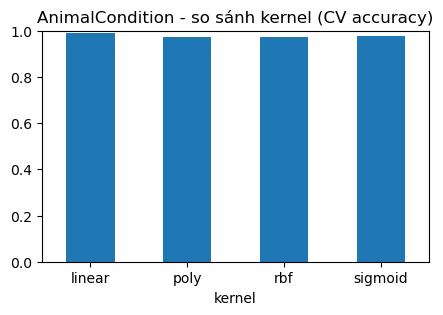

Tham số tốt nhất: {'svc__C': 1, 'svc__kernel': 'linear'}
Accuracy CV: 0.9885
Accuracy train: 1.0000 | Accuracy test: 1.0000 | ROC AUC test: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00       171

    accuracy                           1.00       175
   macro avg       1.00      1.00      1.00       175
weighted avg       1.00      1.00      1.00       175



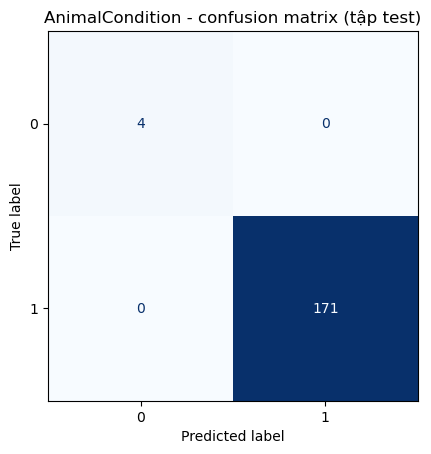

In [18]:
grid2, test2 = run_svm(X2, y2, prep2, 'AnimalCondition')

### Nhận xét kết quả bài 2 – SVM trên dữ liệu tình trạng động vật

**1. So sánh kernel (CV accuracy):** linear cao nhất (0,9885), tiếp theo là sigmoid (0,9785), còn poly và rbf cùng đạt 0,9741. Giá trị 0,9741 gần trùng với tỷ lệ lớp đa số (khoảng 97,7%), cho thấy nhiều khả năng poly và rbf với tham số mặc định gần như dự đoán toàn bộ là Yes. Kernel linear vượt trội vì dữ liệu one-hot nhiều chiều và thưa.

**2. GridSearchCV:** Tham số tốt nhất là kernel linear, C = 1, accuracy kiểm định chéo 0,9885.

**3. Kết quả trên tập test (175 mẫu):** Accuracy train, accuracy test và ROC AUC test đều bằng 1,0000; cả hai lớp đều có precision, recall và F1 bằng 1,00. Tuy nhiên kết quả hoàn hảo này cần diễn giải thận trọng:
- Tập test chỉ có 4 mẫu lớp No và 171 mẫu lớp Yes, nên chỉ cần sai một mẫu No là recall của lớp này đã giảm 25 điểm phần trăm. Với số mẫu ít như vậy thì kết quả 100% chưa chứng minh mô hình luôn đúng.
- Điểm kiểm định chéo (0,9885) thấp hơn điểm test (1,0000), cho thấy ước lượng đáng tin hơn là khoảng 98 đến 99%, và vẫn còn một số mẫu bị phân loại sai ở các fold.
- Accuracy cao hơn mức nền 97,7% chỉ khoảng 1 điểm phần trăm; vì vậy cần xem recall của lớp thiểu số No (con vật không nguy hiểm) bằng nhiều lần kiểm định chéo hoặc kiểm định phân tầng lặp lại.

**4. Hướng cải thiện:** Loại bỏ các dòng thiếu nhãn, thu thêm mẫu lớp No, dùng class_weight=balanced, và báo cáo thêm F1 macro hoặc balanced accuracy để đánh giá công bằng hơn giữa hai lớp.

## 2.4 Số support vectors
Số support vectors cho biết mô hình phức tạp đến đâu (càng nhiều → càng gần ghi nhớ dữ liệu).

In [19]:
svc = grid2.best_estimator_.named_steps['svc']
print('Số support vectors theo lớp:', svc.n_support_, '| tổng =', svc.n_support_.sum(),
      '| tỷ lệ trên tập train = %.1f%%' % (100 * svc.n_support_.sum() / int(len(X2) * 0.8)))

Số support vectors theo lớp: [13 89] | tổng = 102 | tỷ lệ trên tập train = 14.7%


**Nhận xét support vectors:** Mô hình tốt nhất dùng tổng cộng 102 support vectors (13 vector của lớp No và 89 vector của lớp Yes), chiếm khoảng 14,7% tập train. Tỷ lệ này thấp, cho thấy ranh giới phân tách đơn giản, chỉ phụ thuộc vào một phần nhỏ dữ liệu nên mô hình gọn và ít có nguy cơ ghi nhớ toàn bộ dữ liệu. Đáng chú ý, lớp No chỉ có khoảng 17 đến 18 mẫu trong tập train nhưng có tới 13 mẫu trở thành support vector, tức phần lớn mẫu của lớp hiếm này nằm sát biên phân tách.

**Kết luận bài 2:** SVM kernel linear (C = 1) phù hợp với dữ liệu phân loại nhiều chiều sau one-hot, đạt accuracy kiểm định chéo 98,85% và 100% trên tập test. Do nhãn mất cân bằng nặng và tập test chỉ có 4 mẫu lớp thiểu số, cần xem kết quả này là rất tốt nhưng chưa đủ bằng chứng để khẳng định độ chính xác tuyệt đối.

### Nhận xét tổng hợp

| Tiêu chí | Bệnh tiểu đường | Tình trạng động vật |
|---|---|---|
| Loại đặc trưng | Số (và 2 cột phân loại) | Toàn bộ phân loại (one-hot, 1.157 chiều) |
| Cân bằng lớp | 8,5% lớp bệnh | 2,3% lớp No |
| Kernel tốt nhất | rbf (C = 1, gamma = scale) | linear (C = 1) |
| Accuracy kiểm định chéo | 0,9625 | 0,9885 |
| Accuracy test | 0,9550 | 1,0000 |
| Điểm yếu chính | Recall lớp bệnh 0,47 | Tập test lớp thiểu số chỉ 4 mẫu |

Rút ra:
- (1) Chọn kernel phụ thuộc vào dữ liệu: dữ liệu số ít chiều có quan hệ phi tuyến phù hợp rbf, dữ liệu one-hot nhiều chiều và thưa phù hợp linear.
- (2) Chuẩn hóa dữ liệu số và mã hóa đúng dữ liệu phân loại là bắt buộc khi dùng SVM.
- (3) Với dữ liệu mất cân bằng, accuracy dễ gây hiểu lầm vì mức nền đã rất cao; cần xem recall, precision của lớp thiểu số và dùng kiểm định chéo để đánh giá đáng tin hơn một lần chia train/test.